# Nested reports of events with footprints

The truth, geography and model of 07, with one change to how events are recorded. In 07 an event names one unit. In the real record it names every unit its footprint touches at its reporting level, a median of two at ADM2 and up to nine or more, as 08 showed. Here each event center gets a footprint of random size, calibrated to the real record's counts of units named, and the record is fitted two ways: the likelihood of 07, which counts every named unit as an event, and a likelihood with one term per event, in which the event's center lies somewhere in the units it names.

In [1]:
import arviz as az
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
import shapely

from scipy.stats import norm
from tqdm.auto import tqdm

from nested_plotting import LATTICE_EXTENT, draw_borders, plot_fields

from climate_risk.models.aggregation import Aggregation
from climate_risk.plotting import configure_plot_style

configure_plot_style()

# One generator per stage, so rerunning a stage never moves the draws of another. The first six match 07.
SEED = 20261020
GEOGRAPHY_SEED, COLOR_SEED, FIELD_SEED, EVENT_SEED, REPORTING_SEED, OFFSET_SEED, FOOTPRINT_SEED = (SEED + step for step in range(7))

## The geography and the truth

Both exactly as in 07: a 30 by 30 lattice of atoms grouped into 60 ADM2, 12 ADM1 and 3 ADM0 units, and a log rate that is linear in two covariates plus a Matern 3/2 field and nested unit offsets, scaled to the median country's 25 climate-related events per country.

In [2]:
GRID_SIDE = 30
N_ADM2, N_ADM1, N_ADM0 = 60, 12, 3
LLOYD_STEPS = 25
LEVELS = ("ADM2", "ADM1", "ADM0")

n_atoms = GRID_SIDE**2
column, row = (index.ravel() for index in np.meshgrid(np.arange(GRID_SIDE), np.arange(GRID_SIDE)))
atom_x, atom_y = (column + 0.5) / GRID_SIDE, (row + 0.5) / GRID_SIDE
atom_centroids = np.column_stack([atom_x, atom_y])

# Edges as k / GRID_SIDE, computed once per grid line, so neighbors share them exactly and a
# dissolve leaves no slivers between atoms.
edges = np.arange(GRID_SIDE + 1) / GRID_SIDE
atom_cells = gpd.GeoSeries(shapely.box(edges[column], edges[row], edges[column + 1], edges[row + 1]))

In [3]:
def group_into(centroids, n_groups, *, weights, rng):
    """Assign each child to one of ``n_groups`` compact parents, by weighted Lloyd iteration."""
    seeds = centroids[rng.choice(len(centroids), size=n_groups, replace=False)]
    for _ in range(LLOYD_STEPS):
        parent = np.argmin(((centroids[:, None, :] - seeds[None, :, :]) ** 2).sum(axis=-1), axis=1)
        seeds = np.array(
            [np.average(centroids[parent == group], axis=0, weights=weights[parent == group]) for group in range(n_groups)]
        )

    return parent, seeds


geography_rng = np.random.default_rng(GEOGRAPHY_SEED)
adm2_of_atom, adm2_centroids = group_into(atom_centroids,
                                          N_ADM2,
                                          weights=np.ones(n_atoms),
                                          rng=geography_rng)
adm1_of_adm2, adm1_centroids = group_into(adm2_centroids,
                                          N_ADM1,
                                          weights=np.bincount(adm2_of_atom),
                                          rng=geography_rng)
adm0_of_adm1, _ = group_into(adm1_centroids,
                             N_ADM0,
                             weights=np.bincount(adm1_of_adm2[adm2_of_atom]),
                             rng=geography_rng)

unit_of_atom = {
    "ADM2": adm2_of_atom,
    "ADM1": adm1_of_adm2[adm2_of_atom],
    "ADM0": adm0_of_adm1[adm1_of_adm2[adm2_of_atom]],
}
borders = {
    level: gpd.GeoDataFrame({"unit": unit_of_atom[level]}, geometry=atom_cells).dissolve(by="unit").boundary
    for level in LEVELS
}
atoms_per_unit = {level: np.bincount(unit_of_atom[level]) for level in LEVELS}

In [4]:
# Calibrated against EM-DAT in 07: the median country's climate-related events from 1990 to 2023, and the share of
# events at each finest reporting level.
REAL_EVENTS_PER_COUNTRY = 25.0
REAL_LEVEL_SHARES = {"ADM2": 0.43, "ADM1": 0.44, "ADM0": 0.12}

TARGET_EVENTS = round(N_ADM0 * REAL_EVENTS_PER_COUNTRY)
TRUE_SLOPES = np.array([-0.8, 0.5])
COVARIATE_NAMES = ("distance to river", "elevation")
TRUE_FIELD_AMPLITUDE = 0.7
TRUE_FIELD_LENGTHSCALE = 0.12
TRUE_OFFSET_SDS = {"ADM2": 0.3, "ADM1": 0.4, "ADM0": 0.5}
FIELD_JITTER = 1e-8


def standardized(values):
    """Centered and scaled to unit standard deviation."""
    return (values - values.mean()) / values.std()


def matern32(points, *, amplitude, lengthscale):
    """The Matern 3/2 covariance between every pair of ``points``."""
    scaled = np.sqrt(3.0) * np.sqrt(((points[:, None, :] - points[None, :, :]) ** 2).sum(axis=-1)) / lengthscale

    return amplitude**2 * (1.0 + scaled) * np.exp(-scaled)


river_x = 0.5 + 0.2 * np.sin(2.5 * np.pi * atom_y)
elevation = np.sin(3.0 * atom_x + 1.0) * np.cos(2.0 * atom_y) + 0.6 * atom_y
covariates = np.column_stack([standardized(np.abs(atom_x - river_x)), standardized(elevation)])

field_rng = np.random.default_rng(FIELD_SEED)
field_covariance = matern32(atom_centroids, amplitude=TRUE_FIELD_AMPLITUDE, lengthscale=TRUE_FIELD_LENGTHSCALE)
field_covariance[np.diag_indices(n_atoms)] += FIELD_JITTER
true_field = np.linalg.cholesky(field_covariance) @ field_rng.standard_normal(n_atoms)
true_field -= true_field.mean()

offset_rng = np.random.default_rng(OFFSET_SEED)
true_offsets = {
    level: offset_rng.normal(loc=0.0, scale=TRUE_OFFSET_SDS[level], size=len(atoms_per_unit[level])) for level in LEVELS
}
offset_part = sum(true_offsets[level][unit_of_atom[level]] for level in LEVELS)

linear_part = covariates @ TRUE_SLOPES
TRUE_INTERCEPT = float(np.log(TARGET_EVENTS) - np.log(np.exp(linear_part + true_field + offset_part).sum()))
true_log_rate = TRUE_INTERCEPT + linear_part + true_field + offset_part
true_rate = np.exp(true_log_rate)

## Footprints

An event falls at an atom drawn from the true rate, as in 07, and its footprint is a disk around that atom with a log-normal radius. The event is reported at one level, and it names its own unit at that level and each other unit the disk touches with a fixed probability, so footprints can come back in pieces as 08 found. The median radius, the spread of the radius and the naming probability are chosen on a grid so that events reported at ADM2 name as many units as real ones do: 45% name a single unit, and the median, 75th and 90th percentiles are 2, 4 and 9 units.

In [5]:
# Real events reported at ADM2, from 08.
REAL_ADM2_NAMING = {"one unit": 0.45, "median": 2.0, "75%": 4.0, "90%": 9.0}
CALIBRATION_DRAWS = 4_000
MEDIAN_RADII = np.linspace(0.02, 0.2, 10)
RADIUS_SPREADS = (0.5, 0.75, 1.0)
NAMING_PROBABILITIES = (0.5, 0.7, 0.9)

atom_distances = np.sqrt(((atom_centroids[:, None, :] - atom_centroids[None, :, :]) ** 2).sum(axis=-1))


def name_units(center, radius, level, naming_probability, rng):
    """The units at ``level`` an event at ``center`` names: its own, and each other one its footprint touches with ``naming_probability``."""
    touched = np.unique(unit_of_atom[level][atom_distances[center] <= radius])
    own = unit_of_atom[level][center]

    return touched[(touched == own) | (rng.random(len(touched)) < naming_probability)]


def naming_profile(median_radius, radius_spread, naming_probability, rng):
    """How many ADM2 units simulated events name, summarized as ``REAL_ADM2_NAMING`` is."""
    centers = rng.choice(n_atoms, size=CALIBRATION_DRAWS, p=true_rate / true_rate.sum())
    radii = median_radius * np.exp(radius_spread * rng.standard_normal(CALIBRATION_DRAWS))
    named = np.array([len(name_units(center, radius, "ADM2", naming_probability, rng)) for center, radius in zip(centers, radii)])

    return {"one unit": (named == 1).mean(),
            "median": np.median(named),
            "75%": np.quantile(named, 0.75),
            "90%": np.quantile(named, 0.9)}


calibration_rng = np.random.default_rng(FOOTPRINT_SEED)
settings = [(radius, spread, probability) for radius in MEDIAN_RADII for spread in RADIUS_SPREADS for probability in NAMING_PROBABILITIES]
grid = pd.DataFrame([
    {"median radius": radius,
     "radius spread": spread,
     "naming probability": probability,
     **naming_profile(radius, spread, probability, calibration_rng)}
    for radius, spread, probability in tqdm(settings, desc="footprint grid")
])
grid["misfit"] = sum(((grid[key] - target) / target) ** 2 for key, target in REAL_ADM2_NAMING.items())

best = grid.loc[grid["misfit"].idxmin()]
FOOTPRINT_MEDIAN_RADIUS = float(best["median radius"])
FOOTPRINT_RADIUS_SPREAD = float(best["radius spread"])
NAMING_PROBABILITY = float(best["naming probability"])

pd.concat([grid.nsmallest(5, "misfit"), pd.DataFrame([REAL_ADM2_NAMING], index=["real ADM2 events"])]).round(3)

footprint grid:   0%|          | 0/90 [00:00<?, ?it/s]

,median radius,radius spread,naming probability,one unit,median,75%,90%,misfit
25,0.06,1.00,0.70,0.42,2.00,4.00,8.00,0.02
26,0.06,1.00,0.90,0.39,2.00,4.00,10.00,0.03
33,0.08,1.00,0.50,0.38,2.00,4.00,10.00,0.03
23,0.06,0.75,0.90,0.36,2.00,4.00,7.00,0.09
30,0.08,0.75,0.50,0.37,2.00,4.00,6.00,0.15
real ADM2 events,NaN,NaN,NaN,0.45,2.00,4.00,9.00,NaN


The best setting is a median radius of 0.06, about half the width of an ADM2 unit, a log-normal spread of 1.0 and a naming probability of 0.7. It names a single unit for 42% of ADM2 events against 45% in the record, matches the median and 75th percentile exactly, and puts the 90th percentile at 8 units against 9. The wide spread does the work: most footprints stay inside one or two units, and one in ten names eight or more of the 60.

## The record

The operator of 07, with a row for every unit at every level, carries the per-unit counts the 07 likelihood needs: each named unit adds one to its row. The second likelihood needs each event's union, the atoms of all the units it names, and a second operator has one row per event over those atoms. Two regimes are drawn: every event reported at ADM2, and each event's level drawn from the real record's shares. Each is drawn at 07's event count and at ten times it, and within one event count the two regimes share their event centers and footprints.

In [6]:
ALL_LEVELS = ("atom", *LEVELS)
SCALES = (1, 10)
FOOTPRINT_REGIMES = ("ADM2", "mixed")

unit_of_atom["atom"] = np.arange(n_atoms)
n_units = {level: int(unit_of_atom[level].max()) + 1 for level in ALL_LEVELS}
first_row = dict(zip(ALL_LEVELS, np.cumsum([0, *(n_units[level] for level in ALL_LEVELS[:-1])]), strict=True))

reporting = Aggregation(units=tuple(f"{level} {unit}" for level in ALL_LEVELS for unit in range(n_units[level])),
                        rows=np.concatenate([first_row[level] + unit_of_atom[level] for level in ALL_LEVELS]),
                        columns=np.tile(np.arange(n_atoms), len(ALL_LEVELS)),
                        weights=np.ones(n_atoms * len(ALL_LEVELS)),
                        n_cells=n_atoms)


def country_of_units(level):
    """The ADM0 each unit at ``level`` lies in."""
    countries = np.empty(n_units[level], dtype=int)
    countries[unit_of_atom[level]] = unit_of_atom["ADM0"]

    return countries


country_of_row = np.concatenate([country_of_units(level) for level in ALL_LEVELS])
level_of_row = np.repeat(np.arange(len(ALL_LEVELS)), [n_units[level] for level in ALL_LEVELS])


def reports_by_country(counts):
    """Reports at each level in each country, shape ``(country, level)``."""
    table = np.zeros((N_ADM0, len(ALL_LEVELS)))
    np.add.at(table, (country_of_row, level_of_row), counts)

    return table

In [7]:
def draw_centers(rate, rng):
    """One atom per event, as many events at each atom as a Poisson draw from ``rate``."""
    return np.repeat(np.arange(n_atoms), rng.poisson(rate))


def draw_levels(regime, n_events, rng):
    """Each event's reporting level under ``regime``."""
    if regime == "mixed":
        shares = np.array(list(REAL_LEVEL_SHARES.values()))
        return rng.choice(list(REAL_LEVEL_SHARES), size=n_events, p=shares / shares.sum())

    return np.full(n_events, regime)


def draw_record(centers, radii, levels, rng):
    """The per-row count of named units, and an operator with one row per event over the atoms it names."""
    named = [name_units(center, radius, level, NAMING_PROBABILITY, rng) for center, radius, level in zip(centers, radii, levels)]
    counts = np.bincount(np.concatenate([first_row[level] + units for level, units in zip(levels, named)]),
                         minlength=reporting.n_units)

    union_atoms = [np.flatnonzero(np.isin(unit_of_atom[level], units)) for level, units in zip(levels, named)]
    unions = Aggregation(units=tuple(f"event {event}" for event in range(len(centers))),
                         rows=np.repeat(np.arange(len(centers)), [len(atoms) for atoms in union_atoms]),
                         columns=np.concatenate(union_atoms),
                         weights=np.ones(sum(len(atoms) for atoms in union_atoms)),
                         n_cells=n_atoms)

    return {"counts": counts, "unions": unions, "units named": np.array([len(units) for units in named])}


event_rng = np.random.default_rng(EVENT_SEED)
footprint_rng = np.random.default_rng(FOOTPRINT_SEED + 1)
reporting_rng = np.random.default_rng(REPORTING_SEED)

records = {}
for scale in SCALES:
    centers = draw_centers(scale * true_rate, event_rng)
    radii = FOOTPRINT_MEDIAN_RADIUS * np.exp(FOOTPRINT_RADIUS_SPREAD * footprint_rng.standard_normal(len(centers)))
    for regime in FOOTPRINT_REGIMES:
        records[(scale, regime)] = draw_record(centers,
                                               radii,
                                               draw_levels(regime, len(centers), reporting_rng),
                                               reporting_rng)

pd.DataFrame({
    f"{regime}, x{scale}": {
        "events": len(record["units named"]),
        "units named": int(record["units named"].sum()),
        "units named per event, mean": record["units named"].mean(),
        "events naming one unit": (record["units named"] == 1).mean(),
    }
    for (scale, regime), record in records.items()
}).round(2)

,"ADM2, x1","mixed, x1","ADM2, x10","mixed, x10"
events,79.00,79.00,696.00,696.00
units named,271.00,193.00,2823.00,2003.00
"units named per event, mean",3.43,2.44,4.06,2.88
events naming one unit,0.43,0.58,0.42,0.50


## Two likelihoods on one prior

Both models share 07's prior on the log rate: two slopes, a Hilbert-space Matern 3/2 field with $m = 50$ and $c = 4$, and nested unit offsets. They differ only in what they say the record is.

The unit likelihood is 07's: every row is a Poisson count of the units named there, at its country's observed share for its level times the unit's rate. It treats an event naming four units as four events.

The event likelihood treats each event once. The events form a Poisson process with rate $\lambda$, so their number is Poisson with mean $\Lambda = \sum_i \lambda_i$, and each event's center lies in the union $S_e$ of the units it names with probability $\Lambda_{S_e} / \Lambda$, where $\Lambda_{S_e}$ is the rate summed over the union. That is the coarsened-at-random likelihood of Heitjan and Rubin (1991, doi:10.1214/aos/1176348396): it treats where an event's center lies inside its union as uninformative about the rate. The location term is a `pm.CustomDist` whose log density is $\log(\Lambda_{S_e} / \Lambda)$. The reporting shares cancel from it, since every level's share multiplies the same events.

In [8]:
HSGP_BOUNDARY_FACTOR = 4.0
HSGP_BASIS_PER_AXIS = 50
OFFSET_SD_PRIOR = 0.5
sample_kwargs = {
    "chains": 8,
    "cores": 8,
    "tune": 500,
    "draws": 250,
    "target_accept": 0.9,
    "nuts_sampler": "nutpie",
    "random_seed": SEED,
}
COORDS = {
    "covariate": COVARIATE_NAMES,
    "atom": np.arange(n_atoms),
    **{level: np.arange(n_units[level]) for level in LEVELS},
}


def latent_log_rate():
    """The log rate at every atom under 07's prior, built inside the current model."""
    intercept = pm.Normal("intercept",
                          mu=0.0,
                          sigma=2.0)
    slopes = pm.Normal("slopes",
                       mu=0.0,
                       sigma=1.0,
                       dims="covariate")

    # Mode at 0.1 of the domain, about the side of an ADM2 unit, with a tail out past an ADM0.
    field_lengthscale = pm.InverseGamma("field_lengthscale",
                                        alpha=3.0,
                                        beta=0.4)
    field_amplitude = pm.HalfNormal("field_amplitude", sigma=1.0)
    gp = pm.gp.HSGP(m=[HSGP_BASIS_PER_AXIS, HSGP_BASIS_PER_AXIS],
                    c=HSGP_BOUNDARY_FACTOR,
                    cov_func=field_amplitude**2 * pm.gp.cov.Matern32(input_dim=2, ls=field_lengthscale))
    field = gp.prior("field", X=atom_centroids, dims="atom")

    # Summing every level's offsets at the atom nests them: an ADM2's total is its ADM1's plus its own deviation.
    offset_part = 0.0
    for level in LEVELS:
        offset_sd = pm.HalfNormal(f"{level}_offset_sd", sigma=OFFSET_SD_PRIOR)
        standard = pm.Normal(f"{level}_offset_standard",
                             mu=0.0,
                             sigma=1.0,
                             dims=level)
        offsets = pm.Deterministic(f"{level}_offset", offset_sd * standard, dims=level)
        offset_part = offset_part + offsets[unit_of_atom[level]]

    return pm.Deterministic("log_rate",
                            intercept + pm.math.dot(covariates, slopes) + field + offset_part,
                            dims="atom")


def build_unit_model(record):
    """07's likelihood: every named unit a Poisson count at its country's observed share for its level."""
    counts = record["counts"]
    by_country = reports_by_country(counts)
    observed_shares = by_country / by_country.sum(axis=1, keepdims=True)

    with pm.Model(coords=COORDS | {"row": reporting.units}) as model:
        log_rate = latent_log_rate()
        unit_rate = reporting.aggregate_symbolic(pm.math.exp(log_rate))
        pm.Poisson("events",
                   mu=observed_shares[country_of_row, level_of_row] * unit_rate,
                   observed=counts,
                   dims="row")

    return model


def located_logp(value, share):
    """Log probability that an event's center lies in its union, given the union's share of the total rate."""
    return pt.log(share)


def build_event_model(record):
    """One term per event: a Poisson count of events, and each center somewhere in the units the event names."""
    unions = record["unions"]

    with pm.Model(coords=COORDS | {"event": unions.units}) as model:
        log_rate = latent_log_rate()
        rate = pm.math.exp(log_rate)
        total_rate = rate.sum()
        pm.Poisson("event_count",
                   mu=total_rate,
                   observed=unions.n_units)
        pm.CustomDist("event_location",
                      unions.aggregate_symbolic(rate) / total_rate,
                      logp=located_logp,
                      observed=np.zeros(unions.n_units),
                      dims="event")

    return model


BUILDERS = {"unit likelihood": build_unit_model, "event likelihood": build_event_model}

In [9]:
fits = {}
for regime in FOOTPRINT_REGIMES:
    for likelihood, build in BUILDERS.items():
        with build(records[(1, regime)]):
            fits[(1, regime, likelihood)] = pm.sample(**sample_kwargs)

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard]


Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard]


Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard]


Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard]


Output()

In [10]:
for regime in FOOTPRINT_REGIMES:
    for likelihood, build in BUILDERS.items():
        with build(records[(10, regime)]):
            fits[(10, regime, likelihood)] = pm.sample(**sample_kwargs)

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard]


Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard]


Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard]


Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard]


Output()

## What each likelihood recovers

Each fit against two truths. The center rate is the rate events start at, which both likelihoods are written for. The hit rate is the rate a footprint covers an atom, the center rate spread by the footprint's disk, which is the hazard a damage model needs. The table gives each fit's total rate against the true number of event centers, the correlation of its atom log rates with each truth, and how its field, slopes and offsets compare with 07's.

In [11]:
INTERVAL = 0.9
INTERVAL_BOUNDS = ((1 - INTERVAL) / 2, (1 + INTERVAL) / 2)
CONVERGENCE_VARIABLES = ["intercept",
                         "slopes",
                         "field_lengthscale",
                         "field_amplitude",
                         *(f"{level}_offset_sd" for level in LEVELS)]

with np.errstate(divide="ignore"):
    # The chance a footprint centered at one atom covers another, from the log-normal radius.
    cover_probability = norm.sf((np.log(atom_distances) - np.log(FOOTPRINT_MEDIAN_RADIUS)) / FOOTPRINT_RADIUS_SPREAD)
true_hit_rate = cover_probability @ true_rate


def correlation(left, right):
    """Pearson correlation of two arrays."""
    return float(np.corrcoef(left, right)[0, 1])


def posterior_mean(posterior, name):
    """Posterior mean of one variable, as an array."""
    return posterior[name].mean(dim=("chain", "draw")).to_numpy()


def fit_summary(idata, scale):
    """How one fit's atom rates, field and parameters compare with the center rate and the hit rate."""
    posterior = idata.posterior
    log_rate = posterior_mean(posterior, "log_rate")
    log_center_rate = np.log(scale * true_rate)
    lower, upper = posterior["log_rate"].quantile(INTERVAL_BOUNDS, dim=("chain", "draw")).to_numpy()
    slopes = posterior_mean(posterior, "slopes")

    return {
        "total rate / true centers": float(np.exp(posterior["log_rate"]).sum("atom").mean() / (scale * true_rate.sum())),
        "log rate, correlation with center rate": correlation(log_rate, log_center_rate),
        "log rate, correlation with hit rate": correlation(log_rate, np.log(scale * true_hit_rate)),
        f"center log rate, {INTERVAL:.0%} coverage": float(((log_center_rate >= lower) & (log_center_rate <= upper)).mean()),
        "field, correlation with truth": correlation(posterior_mean(posterior, "field"), true_field),
        "field amplitude, mean": float(posterior["field_amplitude"].mean()),
        "field lengthscale, mean": float(posterior["field_lengthscale"].mean()),
        **{f"slope on {name}, mean": float(slope) for name, slope in zip(COVARIATE_NAMES, slopes, strict=True)},
        **{
            f"{level} offsets, correlation with truth": correlation(posterior_mean(posterior, f"{level}_offset"), true_offsets[level])
            for level in ("ADM1", "ADM2")
        },
        "largest r_hat": float(az.summary(idata, var_names=CONVERGENCE_VARIABLES)["r_hat"].max()),
        "divergences": int(idata.sample_stats["diverging"].sum()),
    }


pd.DataFrame({
    f"{regime}, x{scale}, {likelihood.split()[0]}": fit_summary(idata, scale) for (scale, regime, likelihood), idata in fits.items()
}).round(2)

,"ADM2, x1, unit","ADM2, x1, event","mixed, x1, unit","mixed, x1, event","ADM2, x10, unit","ADM2, x10, event","mixed, x10, unit","mixed, x10, event"
total rate / true centers,3.62,1.07,2.58,1.06,3.76,0.93,2.67,0.93
"log rate, correlation with center rate",0.86,0.89,0.87,0.87,0.81,0.95,0.81,0.92
"log rate, correlation with hit rate",0.85,0.86,0.85,0.85,0.97,0.89,0.98,0.90
"center log rate, 90% coverage",0.06,0.90,0.11,0.94,0.02,0.91,0.08,0.90
"field, correlation with truth",0.31,0.43,0.38,0.41,0.23,0.67,0.21,0.56
"field amplitude, mean",0.27,0.52,0.25,0.48,0.81,0.62,0.71,0.56
"field lengthscale, mean",0.22,0.23,0.25,0.21,0.59,0.21,0.52,0.18
"slope on distance to river, mean",-0.21,-0.66,-0.24,-0.59,-0.22,-0.66,-0.24,-0.75
"slope on elevation, mean",0.41,0.98,0.27,1.06,0.33,0.71,0.37,0.80
"ADM1 offsets, correlation with truth",0.03,0.46,0.25,0.28,0.28,0.45,-0.10,0.32


The unit likelihood counts every named unit as an event, so its total rate is 3.6 times the true number of centers at ADM2 and 2.6 times in the mixed record, close to the units named per event in each, and its 90% intervals cover the true center log rate at only 2% to 11% of atoms. The event likelihood's total is within 7% of the truth, and its intervals cover 90% to 94%.

At 79 events both correlate with the center rate at 0.86 to 0.89, and the difference is in level and intervals. At 696 events they separate. The event fits correlate with the center rate at 0.92 to 0.95, while the unit fits correlate with the hit rate at 0.97 to 0.98 and with the center rate at 0.81. The unit fits learn the footprint as part of the field: its lengthscale grows to 0.52 to 0.59 against a true 0.12, its correlation with the true field falls to 0.21 to 0.23, and the slopes shrink toward zero, -0.22 to -0.24 against -0.8 on the river and 0.33 to 0.37 against 0.5 on elevation. The event fits keep the lengthscale near 0.2, as in 07, reach field correlations of 0.56 to 0.67, and put the river slope at -0.59 to -0.75. Their elevation slope runs steep, 0.71 to 1.06, as it did in 07. Neither likelihood recovers the ADM2 offsets, 0.31 at best. At 696 events r_hat reaches 1.08 to 1.20 with up to 15 divergences, so those fits need longer chains before their numbers are final.

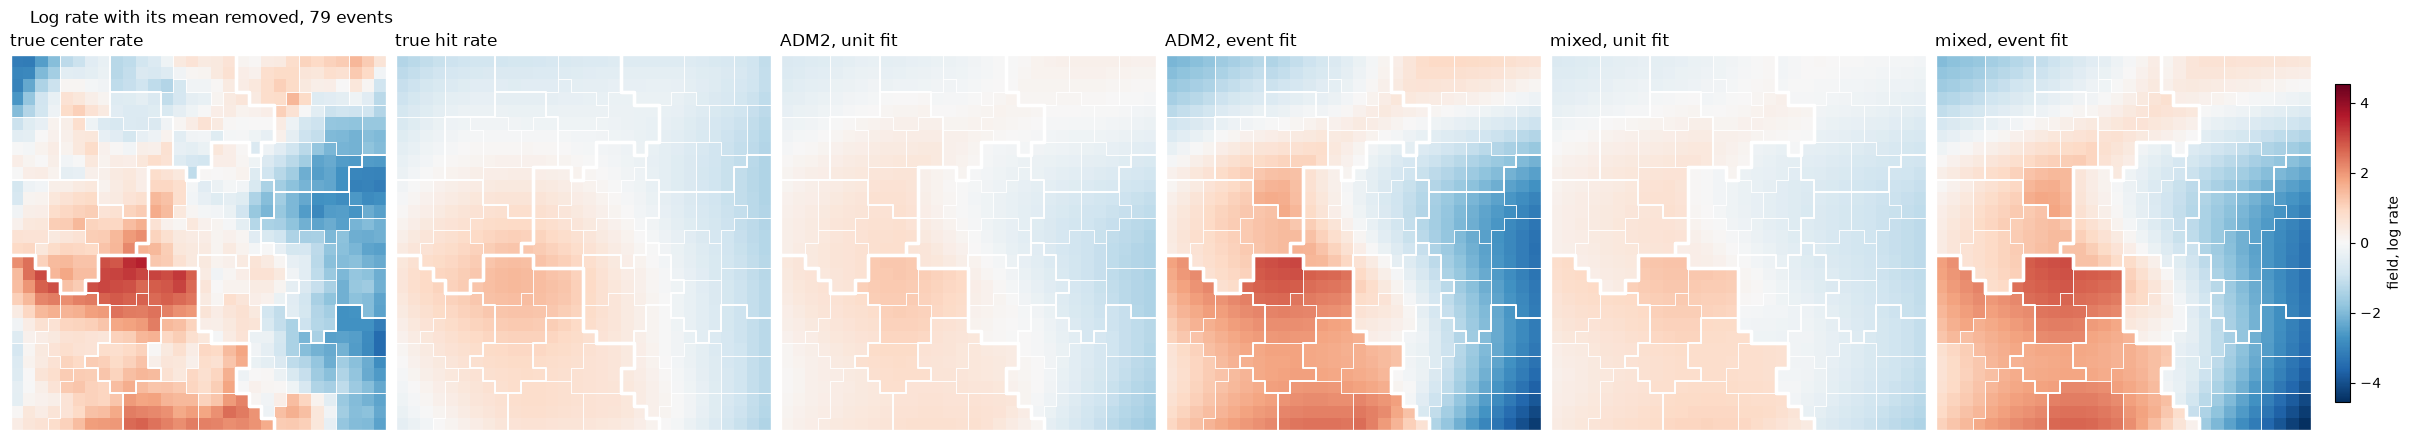

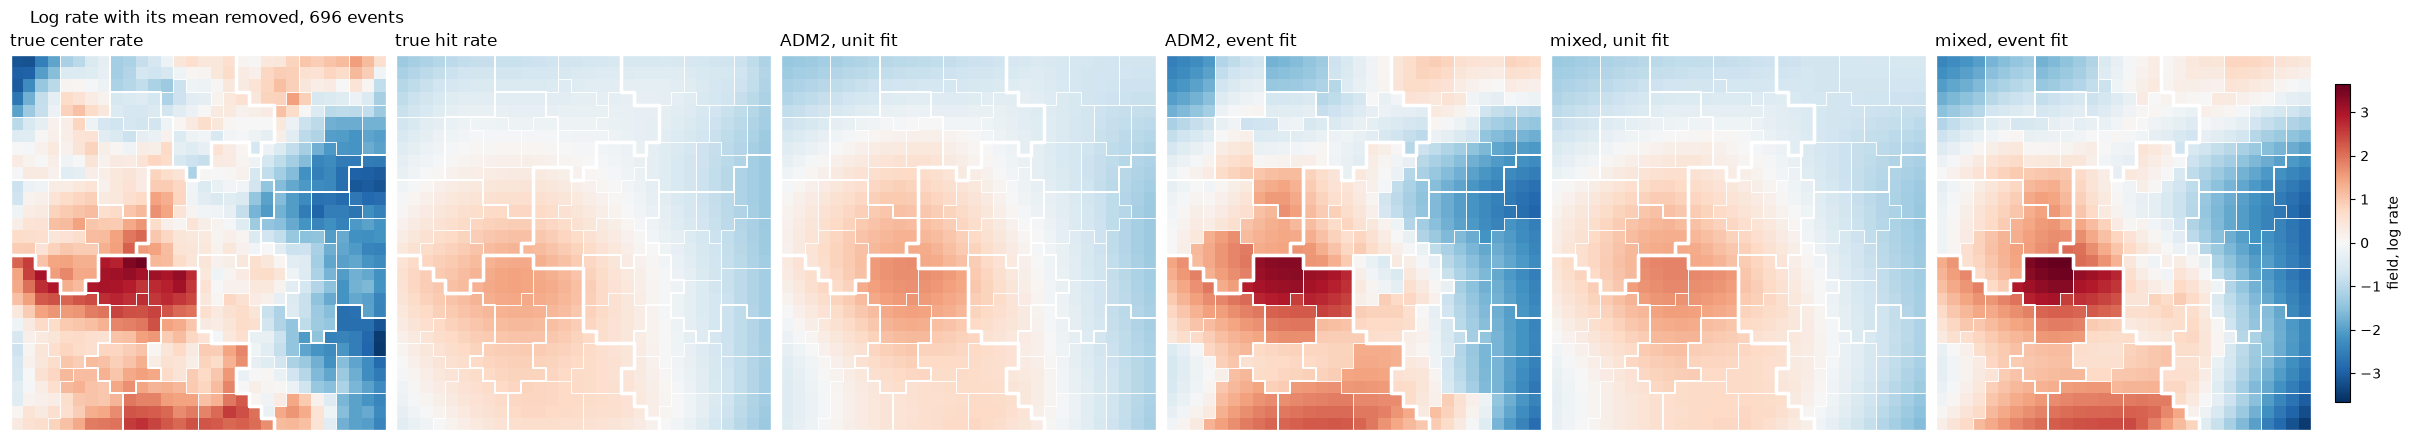

In [12]:
def centered(values):
    """``values`` with their mean removed."""
    return values - values.mean()


for scale in SCALES:
    plot_fields(
        {"true center rate": centered(true_log_rate),
         "true hit rate": centered(np.log(true_hit_rate))}
        | {
            f"{regime}, {likelihood.split()[0]} fit": centered(posterior_mean(fits[(scale, regime, likelihood)].posterior, "log_rate"))
            for regime in FOOTPRINT_REGIMES
            for likelihood in BUILDERS
        },
        borders,
    )
    plt.suptitle(f"Log rate with its mean removed, {len(records[(scale, 'ADM2')]['units named'])} events", x=0.01, ha="left")
    plt.show()

The maps show the same split. The unit fits look like the hit rate, one broad hotspot that runs smoothly across unit borders. The event fits look like the center rate: the western hotspot, the band along the southern edge and the cold east, sharper at 696 events than at 79.

## What this establishes

Counting every named unit as an event gets the model wrong in two ways the fit cannot reveal. It scales the rate by the units named per event, so a record of large footprints looks two to four times as hazardous, and it reads the footprint as spatial structure, so the field is smoothed to the footprint's scale and the covariate slopes shrink toward zero. With more events it converges to the wrong surface, close to the hit rate. Treating each event once, with its center somewhere in the units it names, recovers the center rate's level, intervals that cover it, the river slope and the field. A damage model that needs the hit rate gets it from the center rate and a footprint distribution, which the event likelihood leaves free to model and which 08 shows depends on the hazard. This is one draw at one footprint calibration, and the fits at 696 events have not fully converged.